## 4. Manual Refinement of the Substitution Key

### 4.1 Aim

Part 3 gave a first key for Message 2 by matching the frequency ranks of the ciphertext with those of *Moby Dick*. For this message the decryption starts with `ISERLOCV SOLMEI GREIERKED SNI CALM`. A few words are almost English (for example `CALM`, and further on `TSAT SE` looks like `THAT HE`), but many letters are still wrong. The reason is that one passage does not have the same letter frequencies as a whole novel, so letters with similar counts can end up in the wrong order.

The project booklet expects frequency analysis to come close, but not all the way, for the longer messages. In this section we write a small tool that lets the user swap the roles of any two characters in the key and immediately see the effect on the decoded message. Starting from the Part 3 result, we then adjust the key by hand until the message is readable. We use Message 2, the longest message (1,946 characters, while the next longest, Message 3, has 763), because a long message gives the most words to check each guess against. We then use the same tool on Message 4, which is much shorter, to see how much harder the task becomes.

### 4.2 Method and Mathematical Background

The Part 3 key for Message 2 is a dictionary, which we call `key_2`. Each dictionary key is a ciphertext character and its value is the plaintext character we think it stands for. All 27 characters (A–Z and space) appear exactly once as keys and exactly once as values, so the key is a permutation $\sigma$ of the 27 characters, and the decryption of a ciphertext $c_1c_2\dots c_n$ is

$$
m_i = \sigma(c_i), \qquad i = 1, \dots, n .
$$

Swapping two plaintext characters $a$ and $b$ changes the key to

$$
\sigma' = \tau_{ab} \circ \sigma ,
$$

where $\tau_{ab}$ is the transposition that exchanges $a$ and $b$ and leaves every other character fixed. Since $\tau_{ab}$ and $\sigma$ are both bijections, $\sigma'$ is also a bijection, so after a swap we still have a valid substitution key. Also $\tau_{ab}\circ\tau_{ab}$ is the identity, so making the same swap twice gives back the original key. We use this fact in the tests below.

We swap plaintext characters (the values of the dictionary) rather than ciphertext characters, because the user chooses a swap by reading the decrypted text. One swap changes every position in the message where these two letters appear, not only the word we were looking at. So before keeping a swap we look at several words, not just one.

This leads to three choices in the code. A swap returns a new key and never changes the old one, so a bad guess can simply be dropped. Each swap starts from the last accepted key, so the key improves step by step (in Section 5 we compare this with swaps that all start from the Part 3 key). After every accepted swap we save the key and the full decrypted text, so that Section 5 can score exactly the texts we looked at here.

### 4.3 Implementation and Testing

Part 3 decoded every message in a loop and kept the texts in `first_guesses`, but it did not keep the keys. We need the key for Message 2, so `frequency_key` builds it again in the same way as Part 3, and `frequency_decrypt` applies a key to a whole message. The Metropolis experiments in Section 7 can use them as well. As a check, for every message the two functions together must give back the text in `first_guesses`.

In [10]:
def frequency_key(message):
    """
    Input: message - a ciphertext
    Returns the Part 3 key for this message: the k-th most common ciphertext
    character is mapped to the k-th most common character in Moby Dick
    """
    # Count each character and sort from most to least common, as in Part 3
    cipher_counts = []
    for char in alphabet:
        cipher_counts.append((message.count(char), char))
    cipher_counts.sort(reverse=True)

    key = {}
    for k in range(len(alphabet)):
        key[cipher_counts[k][1]] = paired_list[k][1]
    return key


def frequency_decrypt(message, key):
    """
    Inputs: message - the ciphertext
            key - dictionary {ciphertext character: plaintext character}
    Returns the message decrypted with key
    """
    decrypted = []
    for char in message:
        decrypted.append(key[char])
    return "".join(decrypted)


# Test: for every message, the rebuilt key must give the same text as Part 3
for number in ciphertexts:
    assert frequency_decrypt(ciphertexts[number], frequency_key(ciphertexts[number])) == first_guesses[number]
assert frequency_decrypt("AB A", {"A": " ", "B": "A", " ": "B"}) == " AB "
print("frequency_key and frequency_decrypt give the Part 3 text for all", len(ciphertexts), "messages.")

# The Part 3 key for Message 2, which we refine in this section
key_2 = frequency_key(ciphertexts[2])

frequency_key and frequency_decrypt give the Part 3 text for all 12 messages.


Next we need three pieces of code: a function that makes one swap, a way to look at a swap before keeping it, and a record of the swaps that we keep. We write and test them in this order.

The function below makes one swap. It reads from the old key and writes to a copy. If it changed the dictionary it was reading, an entry changed from `A` to a space could later be changed back to `A`.

In [11]:
def swap_characters(key, char1, char2):
    """
    Inputs: key - dictionary {ciphertext character: plaintext character}
            char1, char2 - the two plaintext characters to exchange
    Returns a new key in which char1 and char2 have swapped places.
    The key given as input is not changed.
    """
    # The two characters must be different and must both be plaintext values in the key
    assert char1 != char2, "Please choose two different characters."
    assert char1 in key.values() and char2 in key.values(), "Both characters must be plaintext values in the key."

    # Work on a copy, so the key we started from stays the same
    new_key = key.copy()

    # Read from the old key and write to the copy
    for cipher_char in key:
        if key[cipher_char] == char1:
            new_key[cipher_char] = char2
        elif key[cipher_char] == char2:
            new_key[cipher_char] = char1

    return new_key

To check `swap_characters` we first use a key small enough to check by hand, including a space. We then try a random pair on the real key of Message 2, so running the cell again tests a different swap. Exactly two entries should change, and making the same swap twice should give back the starting key, since $\tau_{ab}\circ\tau_{ab} = \mathrm{id}$. If the input is not valid, the `assert` lines in `swap_characters` stop the program with our message.

In [12]:
# Tests for swap_characters (run the cell several times to test different random swaps)

# Test 1: a small key we can check by hand (one of the characters is a space)
small_key = {"A": " ", "B": "A", " ": "B"}
small_swap = swap_characters(small_key, "A", " ")
print("Small key before the swap:", small_key)
print("Small key after the swap: ", small_swap)
assert small_swap == {"A": "A", "B": " ", " ": "B"}, "The swap gives the wrong key"
assert small_key == {"A": " ", "B": "A", " ": "B"}, "The original key has been changed"

# Test 2: a random swap on the Part 3 key of Message 2
from random import sample

char1, char2 = sample(alphabet, 2)      # two different random characters
new_key = swap_characters(key_2, char1, char2)
print("\nRandom swap of '" + char1 + "' and '" + char2 + "'")

# Count how many entries of the key have changed
changed = 0
for cipher_char in alphabet:
    if new_key[cipher_char] != key_2[cipher_char]:
        changed = changed + 1
print("Number of entries changed:", changed)

assert changed == 2, "Exactly two entries should change"
assert swap_characters(new_key, char1, char2) == key_2, "Swapping twice should give back the key"
print("All swap tests passed.")

Small key before the swap: {'A': ' ', 'B': 'A', ' ': 'B'}
Small key after the swap:  {'A': 'A', 'B': ' ', ' ': 'B'}

Random swap of 'G' and 'Z'
Number of entries changed: 2
All swap tests passed.


A swap changes letters all over the passage, so before keeping one we want to see what it does. `first_difference` finds the first position where two texts differ (it is used again in Section 5), and `test_swap` prints the same part of the passage before and after the swap, starting just before the first change.

In [13]:
def first_difference(text1, text2):
    """
    Inputs: two strings of the same length
    Returns the first position where they differ, or -1 if they are the same
    """
    for i in range(len(text1)):
        if text1[i] != text2[i]:
            return i
    return -1


def test_swap(message, key, char1, char2):
    """
    Inputs: message - the ciphertext
            key - the key we start from
            char1, char2 - the plaintext characters to swap
    Prints the same part of the decryption before and after the swap.
    Returns the new key and the full new decryption.
    """
    new_key = swap_characters(key, char1, char2)
    before = frequency_decrypt(message, key)
    after = frequency_decrypt(message, new_key)

    # Start the preview 15 characters before the first change
    # (if nothing changes, first_difference gives -1 and we start at 0)
    start = max(0, first_difference(before, after) - 15)
    print("Before:", before[start:start + 90])
    print("After: ", after[start:start + 90])

    return new_key, after

With the small key, the ciphertext `"AB A"` decrypts to `" AB "`, so after swapping `A` and the space it should read `"A BA"`. Then we try the first guess on Message 2, E/T. To try another guess, change the two characters in `preview_pair` and run the cell again (use `" "` for a space). Section 5 scores the same guess.

In [14]:
# Tests for first_difference and test_swap
preview_key, preview_text = test_swap("AB A", small_key, "A", " ")
assert preview_text == "A BA", "test_swap gives the wrong text"
assert preview_key == small_swap, "test_swap gives the wrong key"
assert first_difference("ABC", "ABD") == 2 and first_difference("ABC", "ABC") == -1

# Try a swap on the Part 3 decryption of Message 2.
# Change the two characters here to try a different guess.
message_2 = ciphertexts[2]
preview_pair = ("E", "T")

print("\nTrying", preview_pair[0], "/", preview_pair[1], "on Message 2:")
trial_key, trial_text = test_swap(message_2, key_2, preview_pair[0], preview_pair[1])

Before:  AB 
After:  A BA

Trying E / T on Message 2:
Before: ISERLOCV SOLMEI GREIERKED SNI CALM GROWEIINOHAL MAHHER FHTNL OFR KNINTOR SAD LEWT FI ALTSO
After:  ISTRLOCV SOLMTI GRTITRKTD SNI CALM GROWTIINOHAL MAHHTR FHENL OFR KNINEOR SAD LTWE FI ALESO


Instead of editing the code, the two characters can also be typed in. `input_swap_once` asks once and returns `None` if the input is not valid, catching the `AssertionError` from `swap_characters` so that a typing mistake does not stop the program. `input_swap` keeps asking until the input is valid. A space is typed as the word `SPACE`, since it is hard to see on the screen. Because `input` waits for the keyboard, it only runs when `ask_user` is changed to `True`. Otherwise running all cells would stop here.

In [15]:
def read_character(prompt):
    """
    Input: prompt - the text shown to the user
    Returns the character typed by the user in capitals ("SPACE" gives " ")
    """
    typed = input(prompt).upper()
    if typed == "SPACE":
        return " "
    return typed


def input_swap_once(key):
    """
    Input: key - the key the swap will be applied to
    Prompts the user for two plaintext characters.
    Returns the pair (char1, char2) if the input is valid, otherwise None.
    """
    try:
        char1 = read_character("First character (A-Z or SPACE): ")
        char2 = read_character("Second character (A-Z or SPACE): ")
        assert len(char1) == 1 and len(char2) == 1, "please type one character each time"
        # swap_characters checks the two characters and raises AssertionError if they are wrong
        swap_characters(key, char1, char2)
    except AssertionError as err:
        print("There was an input error: " + str(err))
        return None
    else:
        return (char1, char2)


def input_swap(key):
    """
    Input: key - the key the swap will be applied to
    Prompts the user until two valid characters are typed, then returns them.
    """
    outcome = None
    while outcome is None:
        outcome = input_swap_once(key)
    return outcome

In [16]:
# Change ask_user to True to type a swap yourself
ask_user = False

if ask_user:
    char1, char2 = input_swap(key_2)
    test_swap(message_2, key_2, char1, char2)

### 4.4 Results

The E/T guess above turns the common word `TSE` into `EST`, while S/H turns it into `THE` (and `TSAT` into `THAT`). So we did not keep E/T and started with S/H.

The list below gives the ten swaps we kept, in order, with the clue we saw at that step. Each swap is applied to the key from the step before. We will do the same for a second message later, so the loop is written as a function, `refine`. It returns the key and the full text after every step, and step 0 is the Part 3 result.

In [17]:
def refine(message, start_key, swaps):
    """
    Inputs: message - the ciphertext
            start_key - the key from Part 3
            swaps - list of (char1, char2) pairs in the order we made them
    Applies the swaps one after another and prints a preview of each one.
    Returns two lists: the key and the full decryption after each step
    (step 0 is the starting key).
    """
    # Copy the starting key, so the Part 3 key is never changed
    keys = [start_key.copy()]
    texts = [frequency_decrypt(message, start_key)]

    for step in range(len(swaps)):
        char1 = swaps[step][0]
        char2 = swaps[step][1]
        print("\nStep", step + 1, "-", char1, "/", char2)

        # Start from the last accepted key (keys[-1]), not from the Part 3 key
        new_key, new_text = test_swap(message, keys[-1], char1, char2)
        keys.append(new_key)
        texts.append(new_text)

    return keys, texts


# The swaps we kept, in order. The comment is the clue we saw at that step.
accepted_swaps = [
    ("S", "H"),  # TSE and TSAT suggest THE and THAT.
    ("I", "S"),  # IHERLOCV HOLMEI now suggests a name starting and ending with S.
    ("V", "K"),  # SHERLOCV fits SHERLOCK; GRESERKED also becomes GRESERVED.
    ("G", "P"),  # GRESERVED before "HNS CALM" suggests PRESERVED.
    ("N", "I"),  # HNS CALM and MAIIER can both be read as HIS CALM and MANNER.
    ("F", "U"),  # FNTIL OFR VISITOR makes sense as UNTIL OUR VISITOR.
    ("W", "F"),  # PROWESSIONAL and LEWT suggest PROFESSIONAL and LEFT.
    ("B", "Y"),  # EASB and PROFOUNDLB both look like words ending in Y.
    ("Q", "X"),  # EQCITED suggests EXCITED; XUIET should then read QUIET.
    ("J", "Z"),  # PUJJLED suggests PUZZLED, and FRIEJE becomes FRIEZE.
]

history_keys, history_texts = refine(message_2, key_2, accepted_swaps)


Step 1 - S / H
Before: ISERLOCV SOLMEI GREIERKED SNI CALM GROWEIINOHAL MAHHER FHTNL OFR KNINTOR SAD LEWT FI ALTSO
After:  IHERLOCV HOLMEI GREIERKED HNI CALM GROWEIINOSAL MASSER FSTNL OFR KNINTOR HAD LEWT FI ALTHO

Step 2 - I / S
Before: IHERLOCV HOLMEI GREIERKED HNI CALM GROWEIINOSAL MASSER FSTNL OFR KNINTOR HAD LEWT FI ALTHO
After:  SHERLOCV HOLMES GRESERKED HNS CALM GROWESSNOIAL MAIIER FITNL OFR KNSNTOR HAD LEWT FS ALTHO

Step 3 - V / K
Before: SHERLOCV HOLMES GRESERKED HNS CALM GROWESSNOIAL MAIIER FITNL OFR KNSNTOR HAD LEWT FS ALTHO
After:  SHERLOCK HOLMES GRESERVED HNS CALM GROWESSNOIAL MAIIER FITNL OFR VNSNTOR HAD LEWT FS ALTHO

Step 4 - G / P
Before: HERLOCK HOLMES GRESERVED HNS CALM GROWESSNOIAL MAIIER FITNL OFR VNSNTOR HAD LEWT FS ALTHOF
After:  HERLOCK HOLMES PRESERVED HNS CALM PROWESSNOIAL MAIIER FITNL OFR VNSNTOR HAD LEWT FS ALTHOF

Step 5 - N / I
Before: MES PRESERVED HNS CALM PROWESSNOIAL MAIIER FITNL OFR VNSNTOR HAD LEWT FS ALTHOFGH NT UAS E
After:  MES PRESERVED HIS CAL

Not every guess worked. After step 4 the text contains `MAIIER`, which could be `MATTER`, so we tried I/T. It does give `MATTER`, but `LEWT` becomes `LEWI`, `NT` becomes `NI`, and every `THE` would turn into `IHE`. So we did not keep it and carried on from the step 4 key, which `test_swap` leaves unchanged.

In [18]:
# A guess we tried after step 4 and did not keep
rejected_key, rejected_text = test_swap(message_2, history_keys[4], "I", "T")

Before:  CALM PROWESSNOIAL MAIIER FITNL OFR VNSNTOR HAD LEWT FS ALTHOFGH NT UAS EASB WOR ME UHO KI
After:   CALM PROWESSNOTAL MATTER FTINL OFR VNSNIOR HAD LEWI FS ALIHOFGH NI UAS EASB WOR ME UHO KT


Before using the saved steps we check them: every key must still be one-to-one, every saved text must be the decryption of the message with its key, and from one step to the next only the two chosen characters may change. This is also a function, so that it can check Message 4 later.

In [19]:
def check_steps(message, start_key, swaps, keys, texts):
    """
    Inputs: message - the ciphertext, start_key - the key we started from,
            swaps - the swaps we made, keys and texts - the two lists from refine
    Checks every saved step with assert statements and prints a short summary.
    """
    assert len(keys) == len(swaps) + 1
    assert keys[0] == start_key

    for step in range(len(keys)):
        key = keys[step]

        # Still a valid key: 27 entries and every character is used once as a value
        assert len(key) == 27
        for char in alphabet:
            assert char in key.values(), "A plaintext character is missing from the key"

        # The saved text is the decryption of the message with this key
        assert texts[step] == frequency_decrypt(message, key)

        # From step 1 on, only the two chosen characters may have changed
        if step > 0:
            char1 = swaps[step - 1][0]
            char2 = swaps[step - 1][1]
            old_key = keys[step - 1]
            for cipher_char in alphabet:
                if old_key[cipher_char] == char1:
                    assert key[cipher_char] == char2
                elif old_key[cipher_char] == char2:
                    assert key[cipher_char] == char1
                else:
                    assert key[cipher_char] == old_key[cipher_char]

    print(len(keys), "steps checked, each text has", len(message), "characters.")


check_steps(message_2, key_2, accepted_swaps, history_keys, history_texts)
assert history_texts[0] == first_guesses[2]        # step 0 is the Part 3 text
print("\nFinal raw decryption of Message 2:\n")
print(history_texts[-1])

11 steps checked, each text has 1946 characters.

Final raw decryption of Message 2:

SHERLOCK HOLMES PRESERVED HIS CALM PROFESSIONAL MANNER UNTIL OUR VISITOR HAD LEFT US ALTHOUGH IT WAS EASY FOR ME WHO KNEW HIM SO WELL TO SEE THAT HE WAS PROFOUNDLY EXCITED THE MOMENT THAT HILTON CUBITT S BROAD BACK HAD DISAPPEARED THROUGH THE DOOR MY COMRADE RUSHED TO THE TABLE LAID OUT ALL THE SLIPS OF PAPER CONTAINING DANCING MEN IN FRONT OF HIM AND THREW HIMSELF INTO AN INTRICATE AND ELABORATE CALCULATION FOR TWO HOURS I WATCHED HIM AS HE COVERED SHEET AFTER SHEET OF PAPER WITH FIGURES AND LETTERS SO COMPLETELY ABSORBED IN HIS TASK THAT HE HAD EVIDENTLY FORGOTTEN MY PRESENCE SOMETIMES HE WAS MAKING PROGRESS AND WHISTLED AND SANG AT HIS WORK SOMETIMES HE WAS PUZZLED AND WOULD SIT FOR LONG SPELLS WITH A FURROWED BROW AND A VACANT EYE FINALLY HE SPRANG FROM HIS CHAIR WITH A CRY OF SATISFACTION AND WALKED UP AND DOWN THE ROOM RUBBING HIS HANDS TOGETHER THEN HE WROTE A LONG TELEGRAM UPON A CABLE FORM IF

The final text reads as correct English, so we can use it to measure how much each step helped: for every step we count the percentage of characters that already agree with it. This only describes our own refinement of Message 2. A systematic study of how much adjustment frequency analysis needs in general would be an extension (item 8 in the booklet).

In [20]:
def percent_same(text1, text2):
    """
    Inputs: two strings of the same length
    Returns the percentage of positions where the two strings have the same character
    """
    same = 0
    for i in range(len(text1)):
        if text1[i] == text2[i]:
            same = same + 1
    return 100 * same / len(text1)


def swap_labels(swaps):
    """
    Input: swaps - list of (char1, char2) pairs
    Returns the names of the steps: "base" for step 0, then "S/H" and so on
    """
    labels = ["base"]
    for pair in swaps:
        labels.append(pair[0] + "/" + pair[1])
    return labels


def print_progress(labels, texts):
    """
    Inputs: labels - the name of each step, texts - the decryption after each step
    Prints, for every step, the percentage of characters that agree with the last text
    """
    print("Step  Swap   Characters that agree with the final text")
    for step in range(len(texts)):
        print(f"{step:4}  {labels[step]:4}   {percent_same(texts[step], texts[-1]):6.1f} %")


step_labels = swap_labels(accepted_swaps)
print_progress(step_labels, history_texts)

Step  Swap   Characters that agree with the final text
   0  base     64.8 %
   1  S/H      69.8 %
   2  I/S      75.3 %
   3  V/K      76.6 %
   4  G/P      79.9 %
   5  N/I      90.8 %
   6  F/U      92.8 %
   7  W/F      97.3 %
   8  B/Y      99.5 %
   9  Q/X      99.8 %
  10  J/Z     100.0 %


The Part 3 key already gives 64.8% of the characters correctly, largely because the space was right from the start (none of our swaps involves it). N/I gives the biggest improvement, from 79.9% to 90.8%, as I and N are both common letters, while the last two swaps fix only the rare letters Q, X and Z.

**Message 2 with punctuation and capital letters added by hand**

The passage is from *The Adventure of the Dancing Men* by Arthur Conan Doyle (1903), which is listed in the References. We added the punctuation and capital letters below. Section 5 scores the raw text above.

Sherlock Holmes preserved his calm professional manner until our visitor had left us, although it was easy for me, who knew him so well, to see that he was profoundly excited. The moment that Hilton Cubitt’s broad back had disappeared through the door, my comrade rushed to the table, laid out all the slips of paper containing dancing men in front of him, and threw himself into an intricate and elaborate calculation.

For two hours I watched him as he covered sheet after sheet of paper with figures and letters, so completely absorbed in his task that he had evidently forgotten my presence. Sometimes he was making progress and whistled and sang at his work. Sometimes he was puzzled and would sit for long spells with a furrowed brow and a vacant eye. Finally he sprang from his chair with a cry of satisfaction and walked up and down the room, rubbing his hands together. Then he wrote a long telegram upon a cable form.

“If my answer to this is as I hope, you will have a very pretty case to add to your collection, Watson,” said he. “I expect that we shall be able to go down to Norfolk tomorrow and to take our friend some very definite news as to the secret of his annoyance.”

I confess that I was filled with curiosity, but I was aware that Holmes liked to make his disclosures at his own time and in his own way. So I waited until it should suit him to take me into his confidence. But there was a delay in that answering telegram, and two days of impatience followed, during which Holmes pricked up his ears at every ring of the bell. On the evening of the second there came a letter from Hilton Cubitt. All was quiet with him, save that a long inscription had appeared that morning upon the pedestal of the sundial. He inclosed a copy of it, which is here reproduced. “Elsie, prepare to meet thy God.”

Holmes bent over this grotesque frieze for some minutes and then suddenly sprang to his feet with an exclamation of surprise and dismay. His face was haggard with anxiety.

The raw text has `CUBITT S` because the apostrophe was removed before the message was encrypted.

**A second, shorter message: Message 4**

To check that the tool is not only useful for Message 2, we also refine Message 4, which has 329 characters. We start from its Part 3 key, built with `frequency_key` from Section 4.3.

In [21]:
message_4 = ciphertexts[4]
key_4 = frequency_key(message_4)
print("Part 3 method applied to Message 4:\n")
print(frequency_decrypt(message_4, key_4))

Part 3 method applied to Message 4:

DIRYLOG DLTH THELR EGBVTLNO MISSENGUEA THE CUTMH MIOAUSTNOTA DERE RUOOLOG OUFWERA WIAYNSLAA RISE DNA WNALMNSSB TI CI THE MNSMUSNTLIOA THE AUFA WERCIDAYL ANLC AI DHEO THE ATERO MNFE PREE IO FIOCNB FIROLOG DE MNSMUSNTEC THNT DE AHIUSC SET TIOOEA IP DNTER WNSSNAT LO NT THE RENR IP THE KEAAES TI VUAH THE ATERO CIDO NOC SLPT THE WID


This start is much further from English than for Message 2: apart from `THE`, almost every word is wrong. We used the same tools as before and kept a swap only when it turned several broken words into real ones. The comments give the words we saw.

In [22]:
# The swaps we kept for Message 4, in order, with the clue we saw at that step
swaps_4 = [
    ("N", "A"),  # THNT and RENR suggest THAT and REAR.
    ("M", "C"),  # MAFE suggests CAME, and MASMUSATLION starts like CALCULATIONS.
    ("N", "S"),  # THE NUFN looks like THE SUMS, and CISSEAGUEN should end in S.
    ("I", "O"),  # TI MI THE and SI suggest TO DO THE and SO.
    ("N", "L"),  # CONNEAGUES suggests COLLEAGUES; RONE becomes ROLE.
    ("N", "I"),  # THENR and RUIINIG suggest THEIR and RUNNING.
    ("M", "D"),  # MUTCH, SHOULM and CALCULATEM suggest DUTCH, SHOULD and CALCULATED.
    ("M", "W"),  # MITH, MERE and MHEN suggest WITH, WERE and WHEN.
    ("F", "M"),  # SUFS and FORNING suggest SUMS and MORNING.
    ("F", "B"),  # NUMFERS and FALLAST suggest NUMBERS and BALLAST.
    ("F", "Y"),  # BASICALLF and MONDAF suggest BASICALLY and MONDAY.
    ("V", "P"),  # EGYVTIAN and VUSH suggest EGYPTIAN and PUSH.
    ("V", "F"),  # VREE, LIVT and OV suggest FREE, LIFT and OF.
    ("K", "V"),  # KESSEL suggests VESSEL; WORVING becomes WORKING.
]

keys_4, texts_4 = refine(message_4, key_4, swaps_4)


Step 1 - N / A
Before: TH THELR EGBVTLNO MISSENGUEA THE CUTMH MIOAUSTNOTA DERE RUOOLOG OUFWERA WIAYNSLAA RISE DNA
After:  TH THELR EGBVTLAO MISSEAGUEN THE CUTMH MIONUSTAOTN DERE RUOOLOG OUFWERN WINYASLNN RISE DAN

Step 2 - M / C
Before: THELR EGBVTLAO MISSEAGUEN THE CUTMH MIONUSTAOTN DERE RUOOLOG OUFWERN WINYASLNN RISE DAN WA
After:  THELR EGBVTLAO CISSEAGUEN THE MUTCH CIONUSTAOTN DERE RUOOLOG OUFWERN WINYASLNN RISE DAN WA

Step 3 - N / S
Before: ELR EGBVTLAO CISSEAGUEN THE MUTCH CIONUSTAOTN DERE RUOOLOG OUFWERN WINYASLNN RISE DAN WANL
After:  ELR EGBVTLAO CINNEAGUES THE MUTCH CIOSUNTAOTS DERE RUOOLOG OUFWERS WISYANLSS RINE DAS WASL

Step 4 - I / O
Before: DIRYLOG DLTH THELR EGBVTLAO CINNEAGUES THE MUTCH CIOSUNTAOTS DERE RUOOLOG OUFWERS WISYANLS
After:  DORYLIG DLTH THELR EGBVTLAI CONNEAGUES THE MUTCH COISUNTAITS DERE RUIILIG IUFWERS WOSYANLS

Step 5 - N / L
Before: DORYLIG DLTH THELR EGBVTLAI CONNEAGUES THE MUTCH COISUNTAITS DERE RUIILIG IUFWERS WOSYANLS
After:  DORYNIG DNTH THENR EG

In [23]:
check_steps(message_4, key_4, swaps_4, keys_4, texts_4)
print("\nFinal raw decryption of Message 4:\n")
print(texts_4[-1])
print()
print_progress(swap_labels(swaps_4), texts_4)

15 steps checked, each text has 329 characters.

Final raw decryption of Message 4:

WORKING WITH THEIR EGYPTIAN COLLEAGUES THE DUTCH CONSULTANTS WERE RUNNING NUMBERS BOSKALISS ROLE WAS BASICALLY TO DO THE CALCULATIONS THE SUMS BERDOWSKI SAID SO WHEN THE STERN CAME FREE ON MONDAY MORNING WE CALCULATED THAT WE SHOULD LET TONNES OF WATER BALLAST IN AT THE REAR OF THE VESSEL TO PUSH THE STERN DOWN AND LIFT THE BOW

Step  Swap   Characters that agree with the final text
   0  base     48.9 %
   1  N/A      55.3 %
   2  M/C      58.1 %
   3  N/S      65.0 %
   4  I/O      71.1 %
   5  N/L      76.3 %
   6  N/I      86.6 %
   7  M/D      89.4 %
   8  M/W      92.7 %
   9  F/M      94.2 %
  10  F/B      96.0 %
  11  F/Y      97.0 %
  12  V/P      97.6 %
  13  V/F      98.8 %
  14  K/V     100.0 %


Message 4 needed 14 swaps, compared with 10 for Message 2, and its Part 3 key gets only 48.9% of the characters right (64.8% for Message 2). With fewer characters, the counts in a short message are further from the counts in *Moby Dick*, so more letters start in the wrong place. Again N/I gave the biggest single improvement (from 76.3% to 86.6%). Four letters, J, Q, X and Z, never appear in this plaintext, so the ciphertext characters that stand for them never appear either. Where they belong in the key cannot be found from this message at all.

With punctuation and capital letters added by us, Message 4 reads:

Working with their Egyptian colleagues, the Dutch consultants were running numbers. Boskalis’s role was basically to do the calculations, the sums, Berdowski said. So when the stern came free on Monday morning, we calculated that we should let tonnes of water ballast in at the rear of the vessel to push the stern down and lift the bow.

It reads like part of a news report about freeing a stuck ship. We did not identify the original article.

### 4.5 Discussion and Limitations

After ten swaps the whole of Message 2 can be read, and after fourteen swaps Message 4 can too. What helped most was checking a guess against words that appear many times: S/H fixed both `TSE` and `TSAT` in Message 2, and F/U fixed `FNTIL` and `OFR` together. Some clues only appear far into the passage, such as `PUJJLED` and `FRIEJE` for the last swap, J/Z.

The method also has clear limitations:

- **It depends on the reader.** Each decision is our own judgement, and there is no number that says how much better a swap is. The I/T guess looked good for one word but was bad for the passage as a whole.
- **It needs a long message.** In Message 2 (1,946 characters) most letters appear in many words, so a wrong swap is easy to spot. Message 4 (329 characters) already starts further from the answer, needs more swaps, and leaves four letters of the key undecided. Message 11 has only 12 characters, so there is almost nothing to check a guess against. These are only two examples, not a general study of how the needed adjustment depends on length.
- **It is slow.** Each step has $\binom{27}{2} = 351$ possible swaps and we can only look at a few. Trying every key is impossible: there are $27! \approx 1.09 \times 10^{28}$ keys, which would take about $3 \times 10^{11}$ years even at a billion keys per second.

In Section 5 we therefore build a score from pairs of neighbouring characters, so that candidate decryptions can be compared with a number instead of by eye. The swap tool from this section is still useful later: as the booklet suggests, the key found by the Metropolis algorithm in Question 6 can be adjusted by hand at the end in the same way.

## 5. Scoring a Decryption with Bigrams

### 5.1 Aim

Frequency analysis followed by hand adjustment worked for Message 2, but it is less likely to work for the later messages. They are too short for accurate frequency counts, and some may use unusual language. Choosing swaps by eye is also subjective and cannot be automated: in Section 4, S/H turned `TSE` into `THE` while E/T turned it into `EST`, and only reading the text told them apart. The aim of this section is to write a function that gives any candidate decryption a number, where a higher number means the text looks more like English. We then score every step of Section 4 and test how reliable the score is.

### 5.2 Method and Mathematical Background

We use the order of neighbouring characters. A **bigram** is a pair of characters next to each other, for example `TH`, `HE` or `E ` (E followed by a space). The space is treated like any other character. In ordinary English some pairs, like `TH`, are very common and others, like `QX`, almost never happen.

From the cleaned *Moby Dick* text of Part 2 we count

- $N(a)$: the number of times character $a$ appears,
- $N(ab)$: the number of times character $a$ is immediately followed by character $b$.

We move along the text one position at a time, so the string `AAA` contains two `AA` pairs. Following the project booklet, the probability that $a$ is followed by $b$ is estimated by

$$
p(a,b) = \frac{N(ab) + 1}{N(a)} ,
$$

and the score of a candidate message $m = m_1 m_2 \dots m_n$ is

$$
S(m) = \sum_{i=1}^{n-1} \log p(m_i, m_{i+1}) ,
$$

where $\log$ is the natural logarithm. As the booklet explains, $S(m)$ is the logarithm of the probability of seeing $m$ (given its first character) under a Markov model, in which each character depends only on the character just before it, with $p(a,b)$ as the probability of moving from $a$ to $b$. A few remarks:

- The $+1$ means that a pair which never appears in *Moby Dick* (such as two spaces) still has $p > 0$, so its logarithm is finite. As a result the $p(a,b)$ for a fixed $a$ do not add up to 1, which does not matter for comparing scores.
- Every $p(a,b)$ is less than 1, so every term is negative, and a text with more common pairs has a higher (less negative) score.
- Taking logarithms turns a product of many small probabilities into a sum. The product of almost two thousand numbers below 1 would be too small for the computer to store.
- A text of length $n$ has $n-1$ pairs, so we only compare texts of the same length. All decryptions of Message 2 have the same length.

### 5.3 Implementation and Testing

The score needs two parts: a table of $\log p(a,b)$, built once from *Moby Dick*, and a function that uses this table to score a message. Both go through a text one pair at a time, so we write that step first, as a generator function `gen_bigrams`. It gives the pairs one by one as the `for` loop asks for them, instead of first building a list of all of them, which for the reference text would hold more than a million strings. A generator can only be used once, so we call `gen_bigrams(text)` again each time.

In [24]:
def gen_bigrams(text):
    """
    Input: text - a string
    Returns a generator that generates the neighbouring pairs text[0:2], text[1:3], ...
    (a text of length n gives n - 1 pairs)
    """
    for i in range(len(text) - 1):
        yield text[i:i + 2]


# Tests for gen_bigrams (list() collects everything the generator gives)
print("Pairs in 'THE ':", list(gen_bigrams("THE ")))
assert list(gen_bigrams("THE ")) == ["TH", "HE", "E "]
assert list(gen_bigrams("AAA")) == ["AA", "AA"], "Overlapping pairs must both be counted"
assert list(gen_bigrams("A")) == [], "A single character has no pairs"

Pairs in 'THE ': ['TH', 'HE', 'E ']


Now we build the table of $\log p(a,b)$ for all $27 \times 27 = 729$ pairs, including pairs that never appear. Scoring a message then needs only one dictionary look-up per pair.

In [25]:
import math

# Count how often each single character appears in the cleaned Moby Dick text (Part 2)
character_counts = {}
for char in alphabet:
    character_counts[char] = 0
for char in cleaned_moby:
    character_counts[char] = character_counts[char] + 1

# Start all 27 x 27 = 729 pairs at zero, so pairs that never appear are also in the table
bigram_counts = {}
for first in alphabet:
    for second in alphabet:
        bigram_counts[first + second] = 0

# Count each pair of neighbours
for pair in gen_bigrams(cleaned_moby):
    bigram_counts[pair] = bigram_counts[pair] + 1

# Store log p(a,b) = log((N(ab) + 1) / N(a)) for every pair.
# The logarithms are worked out once here, not every time a message is scored.
bigram_log_weights = {}
for pair in bigram_counts:
    first = pair[0]
    probability = (bigram_counts[pair] + 1) / character_counts[first]
    bigram_log_weights[pair] = math.log(probability)

# Check the tables: every character is counted once, and a text of length L has L - 1 pairs
assert len(character_counts) == 27 and len(bigram_counts) == 729
assert sum(character_counts.values()) == len(cleaned_moby)
assert sum(bigram_counts.values()) == len(cleaned_moby) - 1

print("Characters in the reference text:", len(cleaned_moby))
print("Neighbouring pairs:", sum(bigram_counts.values()))
print("N(T) =", character_counts["T"], "  N(TH) =", bigram_counts["TH"])
print("p(T,H) =", (bigram_counts["TH"] + 1) / character_counts["T"])

Characters in the reference text: 1170352
Neighbouring pairs: 1170351
N(T) = 87996   N(TH) = 31380
p(T,H) = 0.35661848265830265


Later sections, such as the Metropolis experiments in Section 7, call `score_message(text)` with only the text as input. If the function read `bigram_log_weights` as a global variable, changing that variable later (for example in an extension) would silently change every score. Instead, `make_score_function` takes a table and returns a function that always uses that table, so `score_message` is a closure with its table fixed when it is made. The text must only contain capital letters and spaces, because any other character gives a `KeyError`.

In [26]:
def make_score_function(log_weights):
    """
    Input: log_weights - dictionary {pair: log p(a,b)} for all 729 pairs
    Returns: the function score(message), which adds up log p(a,b)
             over all neighbouring pairs of message
    """
    def score(message):
        """
        Input: message - a candidate decryption (capital letters A-Z and spaces only)
        Returns the bigram score S(m). A higher score means more like English.
        """
        total = 0
        # A text of length n has n - 1 pairs, so "" and "A" have no pairs and score 0
        for pair in gen_bigrams(message):
            total = total + log_weights[pair]
        return total
    return score


# The score used in the rest of the project, built from the Moby Dick table
score_message = make_score_function(bigram_log_weights)

To check `score_message` we work out a few scores by hand: `TH` has one term and `THE` has two. Here the string method `count` is safe because `TH`, `HE` and `" T"` cannot overlap with themselves. Two spaces never appear together in the book, so that pair checks the $+1$. `AA` *can* overlap, so we count it with our own loop rather than with `gen_bigrams`, so that the check does not rely on the code it tests.

In [27]:
# Tests for score_message, compared with hand calculations

TOLERANCE = 1e-9

def close(x, y):
    """
    Inputs: two floats x, y
    Returns True if they differ by less than TOLERANCE
    Global variable used: TOLERANCE
    """
    return abs(x - y) < TOLERANCE


p_th = (cleaned_moby.count("TH") + 1) / cleaned_moby.count("T")
p_he = (cleaned_moby.count("HE") + 1) / cleaned_moby.count("H")
p_space_t = (cleaned_moby.count(" T") + 1) / cleaned_moby.count(" ")

assert score_message("") == 0 and score_message("A") == 0             # no pairs at all
assert close(score_message("TH"), math.log(p_th))                       # one pair
assert close(score_message("THE"), math.log(p_th) + math.log(p_he))     # two pairs: TH and HE
assert close(score_message(" T"), math.log(p_space_t))                  # the space is a character too

# Two spaces never appear together in the cleaned book, so only the +1 is left
assert bigram_counts["  "] == 0
assert close(score_message("  "), math.log(1 / character_counts[" "]))

# AA can overlap, so we count it with our own loop
aa_count = 0
for i in range(len(cleaned_moby) - 1):
    if cleaned_moby[i] == "A" and cleaned_moby[i + 1] == "A":
        aa_count = aa_count + 1
p_aa = (aa_count + 1) / character_counts["A"]
assert close(score_message("AAA"), 2 * math.log(p_aa))                  # AAA has two AA pairs

print("All hand-calculated scores agree with score_message.")

All hand-calculated scores agree with score_message.


The formula is implemented correctly, but does the order of the characters really matter? For each example sentence we shuffle its own characters, so the shuffled version has the same letters and spaces and only the order differs. The seed is fixed so that the shuffles are the same on every run.

In [28]:
from random import seed, shuffle

seed(16)    # fixed seed, so the shuffled sentences are the same on every run

examples = ["THE BOAT CAME BACK TO SHORE",
            "WE MET OUTSIDE THE LIBRARY",
            "SHE LEFT THE LETTER ON THE TABLE"]

for sentence in examples:
    characters = list(sentence)
    shuffle(characters)
    shuffled = "".join(characters)

    print(f"{score_message(sentence):8.2f}   {sentence}")
    print(f"{score_message(shuffled):8.2f}   {shuffled}")
    print()

  -57.24   THE BOAT CAME BACK TO SHORE
 -121.94   E OHKHAOEEAO BTC  STBT CRAM

  -59.49   WE MET OUTSIDE THE LIBRARY
  -90.52   SMTAUHR EETED EI OTR WIBLY

  -66.37   SHE LEFT THE LETTER ON THE TABLE
 -115.34   FO   L HT HBALERNETEE EHETLTTETS



Any other text can be scored by changing `my_text` below. It is changed to capitals first, and a character outside the alphabet gives a short message instead of an error. The average score per pair, $S(m)/(n-1)$, can be used to compare texts of different lengths.

In [29]:
# Try your own text here (letters and spaces; it is changed to capitals first)
my_text = "This sentence is written in ordinary English"
my_text = my_text.upper()

try:
    my_score = score_message(my_text)
except KeyError as err:
    print("This pair of characters cannot be scored: " + str(err))
    print("Please use only the letters A-Z and spaces.")
else:
    print("Text:", my_text)
    print("Score S(m):", round(my_score, 3))
    if len(my_text) > 1:
        print("Average score per pair:", round(my_score / (len(my_text) - 1), 3))

Text: THIS SENTENCE IS WRITTEN IN ORDINARY ENGLISH
Score S(m): -101.214
Average score per pair: -2.354


**Time and memory.** Let $L = 1{,}170{,}352$ be the length of the reference text and $n$ the length of the message.

- Building the table takes time $\Theta(L)$, but only once, and the table has just 729 entries.
- `score_message` does one look-up for each of the $n-1$ pairs, so it takes time $\Theta(n)$, independent of $L$.
- Recounting *Moby Dick* for every score would cost $\Theta(L)$ each time: for Message 2 about $1{,}170{,}352 / 1{,}946 \approx 600$ times more work, repeated thousands of times by the Metropolis algorithm in Section 7.

To check $\Theta(n)$ we use a doubling test: doubling the length should roughly double the time. The exact times change from run to run, but the ratios should stay close to 2.

In [30]:
# Doubling test: for a Theta(n) function the ratio of the times should be close to 2
from time import time      # time() gives the current time in seconds

lengths = [20000, 40000, 80000, 160000]
times = []
for n in lengths:
    text = cleaned_moby[:n]
    start = time()             # the time taken is the difference of two calls
    for repeat in range(20):
        score_message(text)
    times.append((time() - start) / 20)      # average time for one score

print("  Length   Time (s)   Ratio to previous")
print(f"{lengths[0]:8}  {times[0]:9.5f}           -")
for i in range(1, len(lengths)):
    print(f"{lengths[i]:8}  {times[i]:9.5f}   {times[i] / times[i - 1]:9.2f}")

  Length   Time (s)   Ratio to previous
   20000    0.00372           -
   40000    0.00736        1.98
   80000    0.01462        1.98
  160000    0.02953        2.02


### 5.4 Results

We need three tables of scores (accepted steps, rejected guess, independent trials). Each row compares a candidate text with another text, so one function, `print_score_table`, prints all three. It takes the score function as an input, so the tables could also be printed with a different score. In the first table step 0 is the Part 3 decryption (the baseline), and "Change" compares each step with the one before.

In [31]:
def changed_part(before, after):
    """
    Inputs: two texts of the same length
    Returns a short piece around the first change, written as 'before -> after'
    """
    position = first_difference(before, after)
    if position == -1:
        return "(no change)"
    start = max(0, position - 5)
    return before[start:position + 10] + " -> " + after[start:position + 10]


def print_score_table(labels, texts, compare_texts, score_function):
    """
    Inputs: labels - the name of each row
            texts - the candidate decryptions
            compare_texts - for each row, the text it is compared with
            score_function - the function used to score a text
    Prints one row per text: label, length, score, change and the changed part.
    """
    print("Swap  Length       Score      Change   Before -> after")
    for i in range(len(texts)):
        score = score_function(texts[i])
        change = score - score_function(compare_texts[i])
        excerpt = changed_part(compare_texts[i], texts[i])
        print(f"{labels[i]:4}  {len(texts[i]):6}  {score:10.3f}  {change:10.3f}   {excerpt}")


# Each step is compared with the step before it (step 0 with itself)
previous_texts = [history_texts[0]] + history_texts[:-1]

print_score_table(step_labels, history_texts, previous_texts, score_message)

# The I/T guess we rejected after step 4, compared with the step 4 text
print("\nRejected guess, compared with step 4:")
print_score_table(["I/T"], [rejected_text], [history_texts[4]], score_message)

Swap  Length       Score      Change   Before -> after
base    1946   -6503.422       0.000   (no change)
S/H     1946   -5967.327     536.095   ISERLOCV SO -> IHERLOCV HO
I/S     1946   -5821.315     146.012   IHERLOCV H -> SHERLOCV H
V/K     1946   -5759.000      62.315   ERLOCV HOLMES G -> ERLOCK HOLMES G
G/P     1946   -5686.606      72.394   LMES GRESERVED  -> LMES PRESERVED 
N/I     1946   -5089.765     596.841   VED HNS CALM PR -> VED HIS CALM PR
F/U     1946   -4898.338     191.427   NNER FNTIL OFR  -> NNER UNTIL OUR 
W/F     1946   -4752.784     145.554   M PROWESSIONAL  -> M PROFESSIONAL 
B/Y     1946   -4584.098     168.686   S EASB FOR ME W -> S EASY FOR ME W
Q/X     1946   -4543.259      40.839   DLY EQCITED THE -> DLY EXCITED THE
J/Z     1946   -4530.782      12.477   AS PUJJLED AND  -> AS PUZZLED AND 

Rejected guess, compared with step 4:
Swap  Length       Score      Change   Before -> after
I/T     1946   -6239.443    -552.837   ESSNOIAL MAIIER -> ESSNOTAL MATTER


The same scores as a graph:

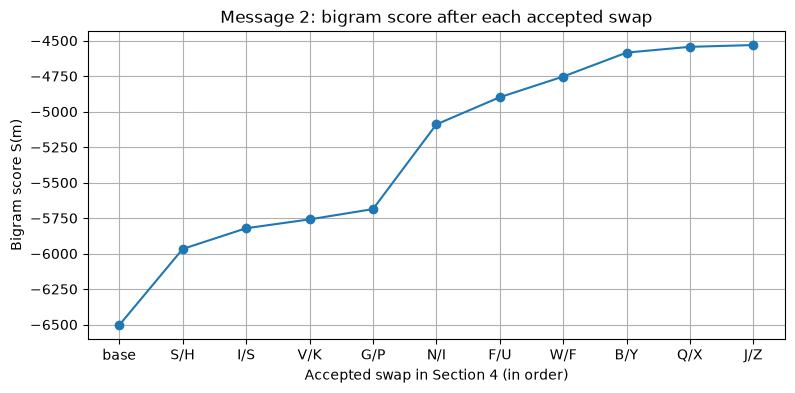

In [32]:
import matplotlib.pyplot as plt

step_scores = []
for text in history_texts:
    step_scores.append(score_message(text))
steps = list(range(len(step_scores)))

plt.figure(figsize=(9, 4))
plt.plot(steps, step_scores, marker="o")
plt.xticks(steps, step_labels)          # write the swap under each point
plt.xlabel("Accepted swap in Section 4 (in order)")
plt.ylabel("Bigram score S(m)")
plt.title("Message 2: bigram score after each accepted swap")
plt.grid(True)
plt.show()

In the independent trials every swap starts again from the Part 3 key, so each change is measured against the baseline. The first row is the guess previewed in Section 4 (E/T unless it was changed), and the other four are swaps our group tried in an earlier draft.

In [33]:
# Every trial starts from the Part 3 key. The first one is the preview from Section 4.
trial_labels = [preview_pair[0] + "/" + preview_pair[1]]
trial_texts = [trial_text]
for pair in [("A", "O"), ("I", "N"), ("S", "H"), ("R", "D")]:
    candidate_key = swap_characters(key_2, pair[0], pair[1])
    trial_labels.append(pair[0] + "/" + pair[1])
    trial_texts.append(frequency_decrypt(message_2, candidate_key))

# Every trial is compared with the step 0 text (the list repeats it once for each trial)
base_texts = [history_texts[0]] * len(trial_texts)
print_score_table(trial_labels, trial_texts, base_texts, score_message)

Swap  Length       Score      Change   Before -> after
E/T     1946   -7191.248    -687.827   ISERLOCV SOL -> ISTRLOCV SOL
A/O     1946   -6724.875    -221.454   ISERLOCV SOLMEI -> ISERLACV SALMEI
I/N     1946   -6165.050     338.372   ISERLOCV S -> NSERLOCV S
S/H     1946   -5967.327     536.095   ISERLOCV SO -> IHERLOCV HO
R/D     1946   -6774.251    -270.829   ISERLOCV SOLM -> ISEDLOCV SOLM


We also score the steps for Message 4 in the same way, again comparing each step with the one before.

In [34]:
previous_texts_4 = [texts_4[0]] + texts_4[:-1]
print_score_table(swap_labels(swaps_4), texts_4, previous_texts_4, score_message)

Swap  Length       Score      Change   Before -> after
base     329   -1035.205       0.000   (no change)
N/A      329    -982.373      52.832   GBVTLNO MISSENG -> GBVTLAO MISSEAG
M/C      329    -958.706      23.667   TLAO MISSEAGUEN -> TLAO CISSEAGUEN
N/S      329    -930.039      28.667   AO CISSEAGUEN T -> AO CINNEAGUES T
I/O      329    -914.905      15.134   DIRYLOG DLT -> DORYLIG DLT
N/L      329    -927.103     -12.198   DORYLIG DLTH T -> DORYNIG DNTH T
N/I      329    -857.819      69.284   DORYNIG DNTH T -> DORYING DITH T
M/D      329    -836.509      21.310   DORYING DI -> MORYING MI
M/W      329    -823.857      12.652   MORYING MI -> WORYING WI
F/M      329    -817.685       6.173   NG NUFMERS MOSY -> NG NUMFERS FOSY
F/B      329    -808.498       9.186   IR EGBVTIAN COL -> IR EGFVTIAN COL
F/Y      329    -802.148       6.350   WORYING WITH  -> WORFING WITH 
V/P      329    -808.406      -6.257   R EGYVTIAN COLL -> R EGYPTIAN COLL
V/F      329    -786.873      21.533   WOR

So far we have only compared candidates we chose ourselves. A harder test is to take the final key of Section 4 and try all 351 swaps: if the score is reliable, every swap that changes the text should lower the score. We repeat this on only the first $n$ characters of Message 2. The shortest part, 12 characters, has the same length as Message 11. "Equal" counts swaps whose letters do not appear in that part, so the text does not change.

In [35]:
def compare_with_single_swaps(ciphertext, key, score_function):
    """
    Inputs: ciphertext - the message (or part of it)
            key - the key we believe is correct
            score_function - the function used to score a text
    Tries every swap of two plaintext characters in key (27 * 26 / 2 = 351 swaps).
    Returns the numbers of swaps that give a lower, an equal and a higher score
    than the decryption with key itself.
    """
    key_score = score_function(frequency_decrypt(ciphertext, key))
    lower = 0
    equal = 0
    higher = 0
    for i in range(len(alphabet)):
        for j in range(i + 1, len(alphabet)):      # every pair of characters once
            new_key = swap_characters(key, alphabet[i], alphabet[j])
            new_score = score_function(frequency_decrypt(ciphertext, new_key))
            if close(new_score, key_score):
                equal = equal + 1
            elif new_score < key_score:
                lower = lower + 1
            else:
                higher = higher + 1
    return lower, equal, higher


final_key = history_keys[-1]
print("Length  Lower  Equal  Higher   Start of the correct decryption")
for n in [12, 30, 100, 300, 1000, len(message_2)]:
    part = message_2[:n]
    lower, equal, higher = compare_with_single_swaps(part, final_key, score_message)
    print(f"{n:6}  {lower:5}  {equal:5}  {higher:6}   {frequency_decrypt(part, final_key)[:30]}")

# The same test on the final key of Message 4 (329 characters)
lower, equal, higher = compare_with_single_swaps(message_4, keys_4[-1], score_message)
print(f"\nMessage 4:  lower {lower}, equal {equal}, higher {higher}")

Length  Lower  Equal  Higher   Start of the correct decryption
    12    184    153      14   SHERLOCK HOL
    30    261     78      12   SHERLOCK HOLMES PRESERVED HIS 
   100    333     15       3   SHERLOCK HOLMES PRESERVED HIS 
   300    348      3       0   SHERLOCK HOLMES PRESERVED HIS 
  1000    350      1       0   SHERLOCK HOLMES PRESERVED HIS 


  1946    351      0       0   SHERLOCK HOLMES PRESERVED HIS 

Message 4:  lower 345, equal 6, higher 0


In [36]:
# One of the wrong swaps that beats the correct text on the first 12 characters
short_part = message_2[:12]
correct_short = frequency_decrypt(short_part, final_key)
wrong_short = frequency_decrypt(short_part, swap_characters(final_key, "A", "O"))

print(f"{score_message(correct_short):8.3f}   {correct_short}   (correct)")
print(f"{score_message(wrong_short):8.3f}   {wrong_short}   (A/O swapped)")

 -29.641   SHERLOCK HOL   (correct)
 -26.473   SHERLACK HAL   (A/O swapped)


### 5.5 Discussion and Limitations

**The score agrees with the manual choices.** All ten accepted swaps raised the score (from −6503.422 to −4530.782), as the share of correct characters rose from 64.8% to 100%, and both rejected guesses, I/T and E/T, lowered it. The largest gain came from N/I (+596.841), which was also the biggest step in Section 4. J/Z added only 12.477 although it fixed `PUZZLED` and `FRIEZE`, because `Z` is rare. So the size of a change shows how many pairs in the passage were affected, not how important a word is to the reader.

**Independent trials.** From the Part 3 key, E/T, A/O and R/D lower the score. I/N raises it by 338.372, although the opening becomes `NSERLOCV SOLMEN`. At step 5 the same swap, made from a different key, gave a larger gain and clearer words. So whether a swap is good depends on the key it is applied to.

**How reliable is the score?** For the whole message all 351 swaps lower the score, so the correct key is a local maximum: no single swap improves it. Since the Metropolis algorithm proposes such swaps, every proposal from this key makes the score worse. The same holds for 300 and 1,000 characters, but not for shorter texts: with 100 characters 3 swaps beat the correct text, and with 12 characters (the length of Message 11) 14 do, for example A/O giving `SHERLACK HAL`, while 153 swaps leave the text unchanged. This confirms with numbers what we suspected in Section 4: for short messages bigrams give too little evidence to find the correct key.

**Message 4.** Over its 14 swaps the score rose from −1035.205 to −776.077, but two correct swaps lowered it for a moment: N/L by 12.198 and V/P by 6.257, even though they fixed `COLLEAGUES` and `EGYPTIAN`. A swap also moves the wrong letter to new places, for example `DLTH` became `DNTH` and `LIPT` became `LIVT`, and in a short message these few rare pairs can outweigh the gain. For the final key, however, no swap gives a higher score: 345 swaps give a lower one, and the 6 equal ones only exchange the four letters J, Q, X and Z, which do not appear. So for a message of this length the score is reliable for the final answer, but not for every single step.

**Shuffled sentences.** Each real sentence scores higher than its shuffled version, so the order of the characters matters. Part of the gap comes from double spaces, which never appear in the book and so cost about $\log(1/218381) \approx -12.3$ each.

**Limitations.**

- The score only looks at neighbouring characters. It cannot tell whether a word is real, and a high score does not prove a decryption is correct.
- Scores can only be compared directly for texts of the same length (otherwise use the average per pair).
- Short messages give too few pairs, as shown above.
- The reference is a 19th-century novel, so text in another style or language may score low even when correct.

The Metropolis experiments in Section 7 use `score_message` to compare keys automatically. Since Section 4 gives the correct answer for Message 2, this is a useful check: there the algorithm reaches the same text with the same score, −4530.782, as our final manual key.